In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, IFrame, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 170)
RES = ROOT / "results"
def show_png(path, width=620):
    display(Image(filename=str(path), width=width))

# 05 · HMM / Viterbi route reconstruction
Code: `hmm/` (`road_graph.py`, `viterbi.py`, `emission.py`, `transition.py`, `decode.py`, `tune.py`, `evaluate.py`).

**Hidden states** – at GPS point *t* the state is one of its candidate arcs (K_t states per step).
**Emission** – `w·log p_clf + (1−w)·log N(dist | 0, σ)`: the classifier probability mixed with a Gaussian on the GPS-to-arc distance.
**Transition** – by hops on the *directed* road graph: same arc, successor (1 hop), 2 hops, 3 hops, U-turn to the reverse twin (rare), else ε (never −∞, so a path always exists).
After a time gap above `gap_s`, extra hops are accepted; a point with no candidates takes the previous arc.
**Viterbi** (log space): `δ_t(j) = e_t(j) + max_i[δ_{t-1}(i) + A_t(i,j)]`, O(T·K²); log space avoids underflow on thousands of points.

## Viterbi on a tiny example worked by hand (also unit-tested)

In [2]:
from hmm.viterbi import viterbi
e = [np.array([0.0, -1.0]), np.array([-2.0, 0.0]), np.array([-5.0, 0.0])]
A = np.array([[0.0, -0.5], [-3.0, 0.0]])
path = viterbi(e, lambda t: A)
print("best state path:", path, "(by hand: [0, 1, 1], score -0.5)")

best state path: [0, 1, 1] (by hand: [0, 1, 1], score -0.5)


## Transition model on a small directed road

In [3]:
from hmm.params import load_params
from hmm.road_graph import RoadGraph
from hmm.transition import transition_matrix
arcs = pd.DataFrame({"from_node": [0,1,2,3,1,2,3,4], "to_node": [1,2,3,4,0,1,2,3]})  # arcs 0-3 east, 4-7 their reverse twins
g = RoadGraph(arcs)
P = load_params()
print("hops 0->3:", g.hops(0, 3), "| twin of arc 0:", g.twin[0], "| successors of arc 0:", g.successors(0).tolist())
M = np.exp(transition_matrix([0], [0,1,2,3,4,7], g, 1.0, P))[0]
print(dict(zip(["same","succ","2 hops","3 hops","U-turn to twin","unconnected"], M.round(6))))

hops 0->3: 3 | twin of arc 0: 4 | successors of arc 0: [1, 4]
{'same': np.float64(0.8), 'succ': np.float64(0.3), '2 hops': np.float64(0.05), '3 hops': np.float64(0.02), 'U-turn to twin': np.float64(0.01), 'unconnected': np.float64(1e-06)}


## Tuned parameters

In [4]:
print("classifier + HMM :", json.dumps(json.loads((ROOT / "artifacts/hmm_config.json").read_text())))
print("distance-only HMM:", json.dumps(json.loads((ROOT / "artifacts/hmm_config_distance.json").read_text())))

classifier + HMM : {"w": 0.3, "sigma_m": 20.0, "heading_sigma_deg": 45.0, "heading_weight": 0.0, "same": 0.8, "succ": 0.3, "hop2": 0.05, "hop3": 0.02, "uturn": 0.01, "eps": 1e-06, "gap_s": 20.0, "gap_extra_hops": 3}
distance-only HMM: {"w": 0.0, "sigma_m": 12.0, "heading_sigma_deg": 45.0, "heading_weight": 0.0, "same": 0.6, "succ": 0.3, "hop2": 0.05, "hop3": 0.02, "uturn": 0.01, "eps": 1e-08, "gap_s": 20.0, "gap_extra_hops": 3}


Decoder parameters were tuned one factor at a time on the **train out-of-fold** probabilities (in-sample probabilities are over-confident) on a seeded sample of clean train trips, then confirmed on student_test.

In [5]:
t = pd.read_csv(RES / "hmm_tuning.csv")
best = t.loc[t.groupby("param").top1.idxmax()][["param","value","top1","continuity"]]
display(best.round(4))
tb = pd.read_csv(RES / "hmm_tuning_distance.csv")
print("Heading term of the distance-only HMM (train sample):")
display(tb[tb.param == "heading_weight"][["value","top1","continuity"]].round(4))

,param,value,top1,continuity
20,eps,0.0000,0.9355,0.9802
22,gap_s,5.0000,0.9355,0.9802
12,same,0.8000,0.9355,0.9802
7,sigma_m,8.0000,0.9341,0.9801
14,succ,0.3000,0.9355,0.9802
16,uturn,0.0001,0.9355,0.9802
1,w,0.3000,0.9341,0.9801


Heading term of the distance-only HMM (train sample):


,value,top1,continuity
0,0.00,0.9111,0.9896
1,0.25,0.9060,0.9889
2,0.50,0.8959,0.9866
3,1.00,0.8756,0.9743


## Classifier-only vs HMM on student_test

,method,trips,points,top1,macro_f1,route_continuity,wrong_direction_rate,trips_ge90_share,eps_transition_share,decode_s_per_trip
0,nearest_arc,10,19160,0.5395,0.7227,0.8201,0.3506,0.0,NaN,0.0000
1,classifier_only(model),10,19160,0.8586,0.9176,0.9370,0.0658,0.4,NaN,0.0065
2,classifier_only(alt),10,19160,0.8561,0.9161,0.9323,0.0653,0.4,NaN,0.0049
3,hmm_distance,10,19160,0.9300,0.9602,0.9949,0.0279,0.7,0.0008,0.3199
4,hmm_classifier(model),10,19160,0.9314,0.9609,0.9854,0.0360,0.8,0.0008,0.4127
5,hmm_classifier(alt),10,19160,0.9395,0.9656,0.9874,0.0245,0.8,0.0008,0.4044


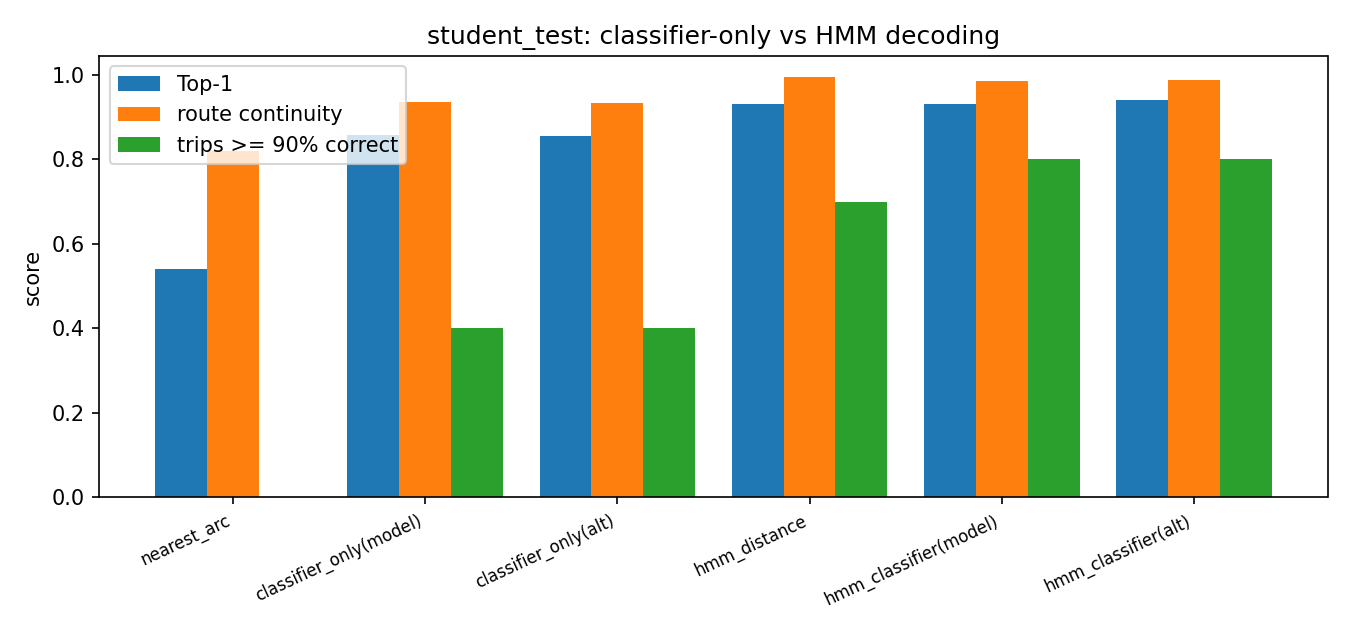

Top-1: classifier-only 0.8586 -> classifier+HMM 0.9314; continuity 0.9370 -> 0.9854
share of chosen transitions that fell back to epsilon (disconnected jump): 0.0008


In [6]:
r = pd.read_csv(RES / "hmm_results.csv")
display(r.drop(columns=["params","split"]).round(4))
show_png(RES / "figures/hmm_comparison.png", 680)
c = r.set_index("method")
print(f"Top-1: classifier-only {c.loc['classifier_only(model)','top1']:.4f} -> classifier+HMM {c.loc['hmm_classifier(model)','top1']:.4f}; "
      f"continuity {c.loc['classifier_only(model)','route_continuity']:.4f} -> {c.loc['hmm_classifier(model)','route_continuity']:.4f}")
print(f"share of chosen transitions that fell back to epsilon (disconnected jump): {c.loc['hmm_classifier(model)','eps_transition_share']:.4f}")

## Per-trip results and the trips where the HMM helped least

In [7]:
pt = pd.read_csv(RES / "hmm_per_trip.csv", dtype={"trip": str})
display(pt.pivot(index="trip", columns="method", values="top1").round(3))
f = pd.read_csv(RES / "hmm_failures.csv", dtype={"trip": str})
display(f)
print("Negative top1_loss means the HMM still improved Top-1 on that trip; it is a ranking of the smallest gains.")
cmp = pt.pivot(index="trip", columns="method", values="top1")
print("trips where classifier+HMM is worse than the distance-only HMM:", cmp.index[cmp["hmm_classifier(model)"] < cmp["hmm_distance"]].tolist())

method,classifier_only(alt),classifier_only(model),hmm_classifier(alt),hmm_classifier(model),hmm_distance,nearest_arc
trip,,,,,,
00000000,0.938,0.941,0.969,0.968,0.969,0.545
00000007,0.923,0.928,0.993,0.994,0.993,0.453
00000009,0.866,0.867,0.910,0.914,0.871,0.537
00000040,0.923,0.924,0.980,0.980,0.992,0.548
00000052,0.958,0.966,0.996,0.989,0.954,0.771
00000056,0.889,0.891,0.954,0.959,0.923,0.691
00000065,0.833,0.832,0.879,0.876,0.839,0.689
00000076,0.859,0.865,0.958,0.961,0.935,0.417
00000077,0.690,0.693,0.867,0.821,0.874,0.403


,trip,points,top1_loss_vs_classifier_only,disagreement_point_ranges
0,00000052,262,-0.0229,52-55; 5-6; 23-23; 17-17
1,00000000,2503,-0.0272,2454-2468; 2479-2484; 2491-2495; 2200-2204; 20...
2,00000065,768,-0.0443,239-242; 735-737; 722-724; 136-138; 690-691


Negative top1_loss means the HMM still improved Top-1 on that trip; it is a ranking of the smallest gains.
trips where classifier+HMM is worse than the distance-only HMM: ['00000000', '00000040', '00000077']


## Where the HMM helps (reference route green, classifier-only orange dashed, HMM red)

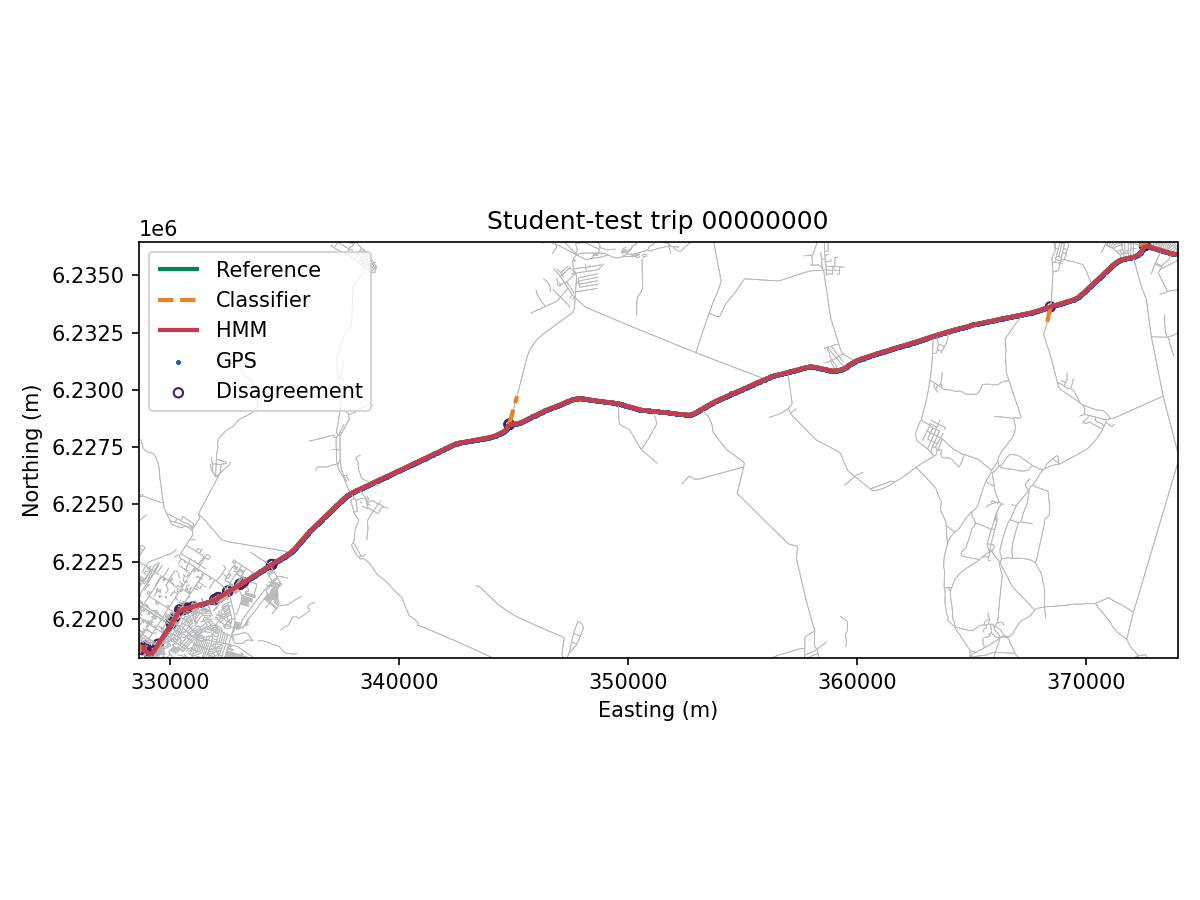

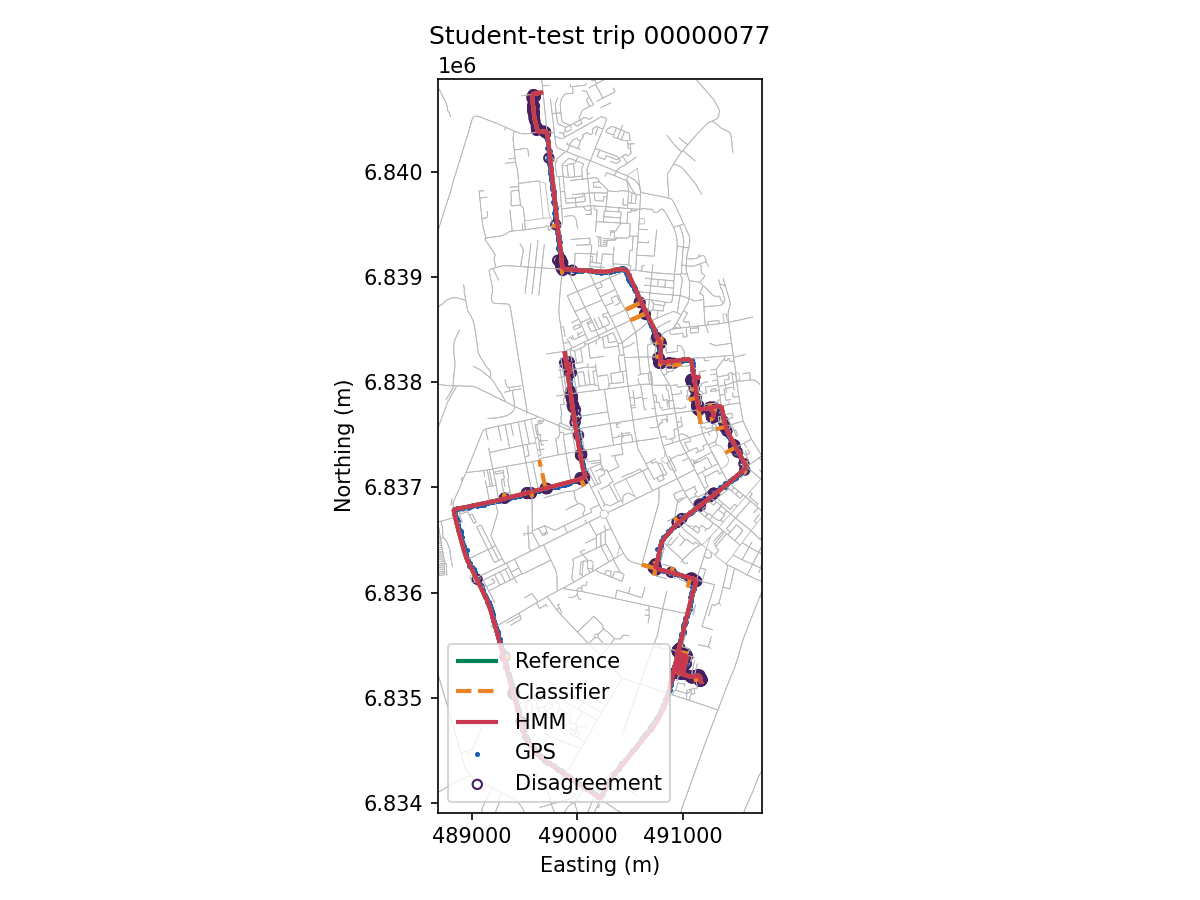

In [8]:
for t in ["00000000", "00000077"]:
    show_png(RES / f"figures/pred_{t}.png", 700)

Interactive Folium maps with layer controls for all ten student_test trips are in `visualisations/maps/pred_<trip>.html` (generated by `python -m visualisations.plot_prediction`).